In [6]:
from pathlib import Path

import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from pyrosm import OSM
from shapely.ops import unary_union

# Notebook находится в day03_polygons/notebooks/
ROOT = Path.cwd().resolve().parent
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"

PROCESSED.mkdir(parents=True, exist_ok=True)

osm = OSM(str(RAW / "uzbekistan-261102.osm.pbf"))

### Part 1: Tashkent Region Boundaries

In [7]:
admin_boundaries = osm.get_boundaries(
    boundary_type="administrative",
    custom_filter={"admin_level": ["4"]}
)

print(f"Found: {len(admin_boundaries)} boundaries")

display(
    admin_boundaries[
        ["id", "name", "admin_level"]
    ]
)

Found: 36 boundaries


,id,name,admin_level
0,85104648,NaN,4
1,102389518,NaN,4
2,168963922,NaN,4
3,183816016,NaN,4
4,402579722,Каракамыш,4
5,524894102,NaN,4
6,607458773,NaN,4
7,629593941,Достык,4
8,629593947,Достык,4
9,791145176,NaN,4


In [8]:
target_ids = {196251, 2216724}

selected = admin_boundaries[
    admin_boundaries["id"].abs().isin(target_ids)
].copy()

print("Selected:", len(selected))
display(selected[["id", "name"]])

assert len(selected) == 2, (
    "Не удалось найти обе границы. "
    "Проверь таблицу admin_boundaries и OSM IDs."
)

Selected: 2


,id,name
29,196251,Toshkent Viloyati
34,2216724,Toshkent


In [9]:
combined_geometry = unary_union(selected.geometry)

tashkent = gpd.GeoDataFrame(
    {
        "name": ["Tashkent Region + City"],
        "geometry": [combined_geometry]
    },
    crs=selected.crs
)

tashkent.to_file(
    PROCESSED / "tashkent_boundary.gpkg",
    driver="GPKG"
)

### Part 2: Extraction of Peaks

In [41]:
peaks = osm.get_natural(
    custom_filter={"natural": ["peak"]},
    extra_attributes=["name", "name:ru", "name:en", "ele"]
)
print(f"All OSM peak features: {len(peaks)}")

display(peaks.head())

All OSM peak features: 3279


,id,lon,lat,tags,visible,version,timestamp,changeset,natural,name,name:ru,name:en,ele,geometry,osm_type
0,296079552,72.391368,40.682866,"{""gns:dsg"":""MT: mountain"",""gns:ufi"":""-2575621""...",True,5,1682774769,0.0,peak,Besh-Buz,Беш-Буз,Besh-Buz,NaN,POINT (72.39137 40.68287),node
1,296079612,72.471924,40.721912,"{""gns:dsg"":""MT: mountain"",""gns:ufi"":""-2577905""...",True,3,1393487129,0.0,peak,Kyzyl-Chek,Кызыл-Чек,Kyzyl-Chek,NaN,POINT (72.47192 40.72191),node
2,296083544,72.565893,40.536027,NaN,True,3,1302363099,0.0,peak,Kaklik-Uchar Gora,NaN,NaN,NaN,POINT (72.56589 40.53603),node
3,349004306,71.283117,42.208347,NaN,True,3,1785799931,0.0,peak,NaN,NaN,NaN,4108.2,POINT (71.28312 42.20835),node
4,349004321,71.124535,42.283465,NaN,True,3,1388033323,0.0,peak,NaN,NaN,NaN,NaN,POINT (71.12454 42.28347),node


In [42]:
peaks["elevation_m"] = pd.to_numeric(
    peaks["ele"]
        .astype("string")
        .str.replace(",", ".", regex=False)
        .str.extract(r"(-?\d+(?:\.\d+)?)")[0],
    errors="coerce"
)

print("Missing elevations:", peaks["elevation_m"].isna().sum())

peaks_1800 = peaks[
    (peaks["elevation_m"] >= 1800) &
    (peaks.geometry.geom_type == "Point")
].copy()

print("Peaks ≥1800 m:", len(peaks_1800))

Missing elevations: 1694
Peaks ≥1800 m: 946


In [43]:
DEM_DIR = (
    ROOT.parent
    / "day02_lines"
    / "data"
    / "raw"
    / "dem"
)

dem_files = sorted(DEM_DIR.glob("*.tif"))

print(f"Found {len(dem_files)} DEM tiles")

Found 84 DEM tiles


In [44]:
print(peaks.geometry.geom_type.value_counts())

Point         3277
LineString       2
Name: count, dtype: int64


In [45]:
import numpy as np

peaks["ele_dem"] = np.nan

peaks = peaks[
    peaks.geometry.geom_type == "Point"
].copy()

peaks = peaks.reset_index(drop=True)

print(f"Point peaks: {len(peaks)}")


Point peaks: 3277


In [46]:
import rasterio
from rasterio.warp import transform_bounds
from shapely.geometry import box

peaks["ele_osm"] = pd.to_numeric(
    peaks["ele"]
        .astype("string")
        .str.replace(",", ".", regex=False)
        .str.extract(r"(-?\d+(?:\.\d+)?)")[0],
    errors="coerce"
)


for dem_file in dem_files:
    with rasterio.open(dem_file) as src:
        # Границы тайла в системе координат вершин
        bounds = transform_bounds(
            src.crs,
            peaks.crs,
            *src.bounds
        )

        mask = peaks.geometry.intersects(box(*bounds))
        subset = peaks.loc[mask]

        if subset.empty:
            continue

        # Переводим координаты точек в CRS растра
        subset_dem = subset.to_crs(src.crs)

        coords = [
            (geom.x, geom.y)
            for geom in subset_dem.geometry
        ]

        values = np.array(
            [v[0] for v in src.sample(coords, masked=True)],
            dtype=float
        )

        if src.nodata is not None:
            values[np.isclose(values, src.nodata)] = np.nan

        # Не перезаписываем уже полученные значения
        missing = peaks.loc[subset.index, "ele_dem"].isna()

        peaks.loc[
            subset.index[missing],
            "ele_dem"
        ] = values[missing.to_numpy()]

print("DEM elevations:", peaks["ele_dem"].notna().sum())

DEM elevations: 3277


In [47]:
peaks["elevation_m"] = peaks["ele_osm"].fillna(
    peaks["ele_dem"]
)

peaks["elevation_source"] = np.select(
    [
        peaks["ele_osm"].notna(),
        peaks["ele_dem"].notna()
    ],
    ["OSM", "DEM"],
    default="MISSING"
)

print(peaks["elevation_source"].value_counts())

peaks_1800 = peaks[
    peaks["elevation_m"] >= 1800
].copy()

print("Peaks >=1800m:", len(peaks_1800))

elevation_source
DEM    1692
OSM    1585
Name: count, dtype: int64
Peaks >=1800m: 2189


In [48]:
print("DEM coverage:", peaks["ele_dem"].notna().mean())

print(
    peaks.groupby("elevation_source")
    .agg(
        count=("id", "count"),
        mean_elevation=("elevation_m", "mean"),
        max_elevation=("elevation_m", "max")
    )
)

DEM coverage: 1.0
                  count  mean_elevation  max_elevation
elevation_source                                      
DEM                1692     2484.216192    4477.632324
OSM                1585     2136.459874         4819.0


In [49]:
comparison = peaks.dropna(
    subset=["ele_osm", "ele_dem"]
).copy()

comparison["diff_m"] = (
    comparison["ele_osm"] - comparison["ele_dem"]
)

display(
    comparison["diff_m"]
    .abs()
    .describe(percentiles=[0.5, 0.9, 0.95, 0.99])
)

print(
    "Differences >100 m:",
    (comparison["diff_m"].abs() > 100).sum()
)

count        1585.0
mean      23.139089
std       55.415986
min        0.015424
50%         9.85481
90%       43.726514
95%       76.784819
99%      296.607578
max      898.940332
Name: diff_m, dtype: Float64

Differences >100 m: 63


In [50]:
threshold_conflicts = peaks[
    peaks["ele_osm"].notna()
    & peaks["ele_dem"].notna()
    & (
        (peaks["ele_osm"] >= 1800)
        != (peaks["ele_dem"] >= 1800)
    )
].copy()

print("Threshold conflicts:", len(threshold_conflicts))

Threshold conflicts: 12


In [51]:
peaks[peaks["elevation_m"] == 4819]

,id,lon,lat,tags,visible,version,timestamp,changeset,natural,name,name:ru,name:en,ele,geometry,osm_type,elevation_m,ele_dem,ele_osm,elevation_source
2927,5610389424,68.177543,39.17849,"{""westra_ref"":""10162""}",True,2,1555095246,0.0,peak,Зиндон,NaN,NaN,4819,POINT (68.17754 39.17849),node,4819.0,4792.459473,4819.0,OSM


In [52]:
display(
    selected[["id", "name", "admin_level", "geometry"]]
)

print("Selected boundaries:", len(selected))
print("CRS:", selected.crs)
print("Valid geometries:", selected.geometry.is_valid.tolist())
print("Combined geometry:", tashkent.geometry.iloc[0].geom_type)
print("Bounds:", tashkent.total_bounds)

,id,name,admin_level,geometry
29,196251,Toshkent Viloyati,4,"POLYGON ((68.64256 40.94334, 68.64167 40.94384..."
34,2216724,Toshkent,4,"MULTIPOLYGON (((69.12232 41.26607, 69.12258 41..."


Selected boundaries: 2
CRS: {"$schema": "https://proj.org/schemas/v0.7/projjson.schema.json", "type": "GeographicCRS", "name": "WGS 84", "datum_ensemble": {"name": "World Geodetic System 1984 ensemble", "members": [{"name": "World Geodetic System 1984 (Transit)"}, {"name": "World Geodetic System 1984 (G730)"}, {"name": "World Geodetic System 1984 (G873)"}, {"name": "World Geodetic System 1984 (G1150)"}, {"name": "World Geodetic System 1984 (G1674)"}, {"name": "World Geodetic System 1984 (G1762)"}, {"name": "World Geodetic System 1984 (G2139)"}, {"name": "World Geodetic System 1984 (G2296)"}], "ellipsoid": {"name": "WGS 84", "semi_major_axis": 6378137, "inverse_flattening": 298.257223563}, "accuracy": "2.0", "id": {"authority": "EPSG", "code": 6326}}, "coordinate_system": {"subtype": "ellipsoidal", "axis": [{"name": "Geodetic latitude", "abbreviation": "Lat", "direction": "north", "unit": "degree"}, {"name": "Geodetic longitude", "abbreviation": "Lon", "direction": "east", "unit": "degr

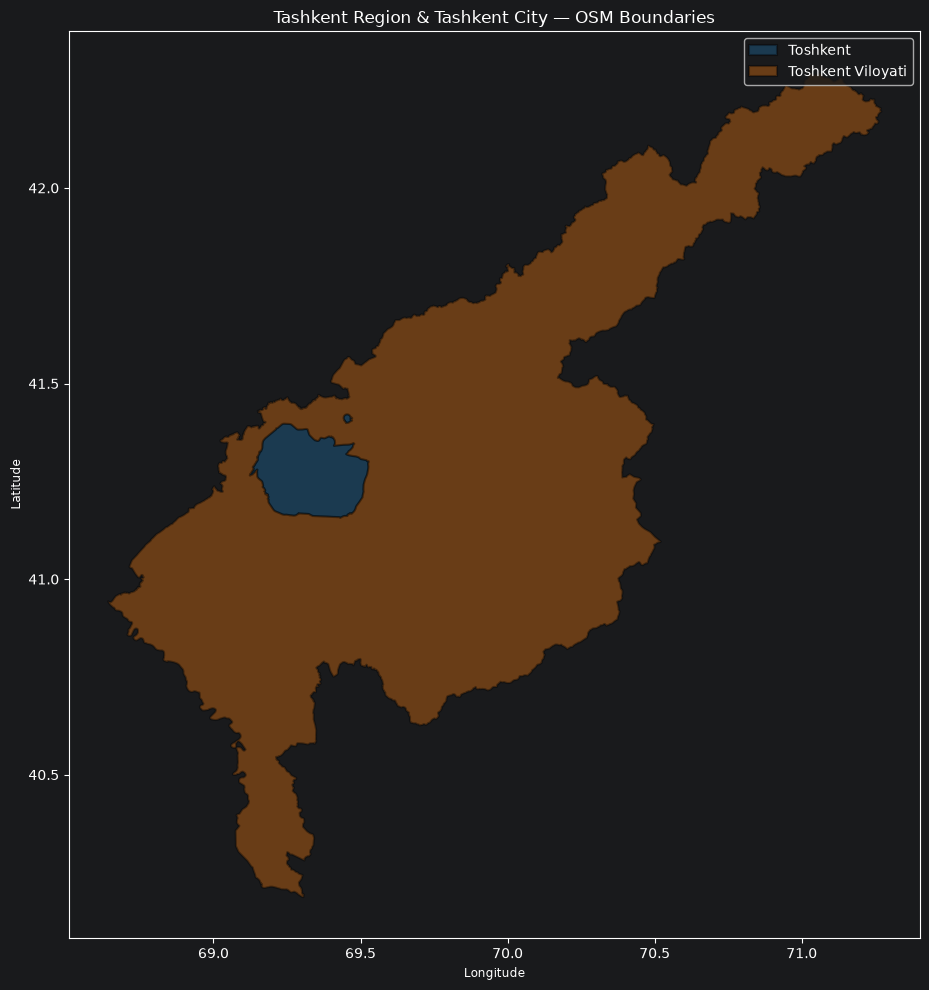

In [53]:
fig, ax = plt.subplots(figsize=(12, 10))

selected.plot(
    ax=ax,
    column="name",
    categorical=True,
    legend=True,
    alpha=0.35,
    edgecolor="black",
    linewidth=1.5
)

ax.set_title("Tashkent Region & Tashkent City — OSM Boundaries")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.tight_layout()
plt.show()

In [54]:
# Приводим к одному CRS
peaks_check = peaks.to_crs(tashkent.crs)

# Отмечаем принадлежность территории
peaks_check["inside_tashkent"] = (
    peaks_check.geometry.intersects(
        tashkent.geometry.iloc[0]
    )
)

print(
    peaks_check["inside_tashkent"].value_counts()
)

# Вершины внутри области
peaks_tashkent = peaks_check[
    peaks_check["inside_tashkent"]
].copy()

display(
    peaks_tashkent[
        ["name", "elevation_m"]
    ].sort_values(
        "elevation_m",
        ascending=False
    ).head(15)
)

inside_tashkent
True     2054
False    1223
Name: count, dtype: int64


,name,elevation_m
1863,Пик Ильяса Тухватуллина,4395.5
1890,NaN,4364.5
1830,NaN,4359.7
1790,NaN,4358.4
1864,Истиклол 4387м,4335.90332
319,NaN,4319.837891
1831,Шавур-Сай,4319.0
1773,NaN,4302.8
1952,NaN,4301.8
1926,NaN,4300.462402


In [55]:
print(peaks_tashkent.columns.tolist())

['id', 'lon', 'lat', 'tags', 'visible', 'version', 'timestamp', 'changeset', 'natural', 'name', 'name:ru', 'name:en', 'ele', 'geometry', 'osm_type', 'elevation_m', 'ele_dem', 'ele_osm', 'elevation_source', 'inside_tashkent']


In [56]:
import folium

# Центр по геометрии территории
center = tashkent.to_crs(4326).geometry.iloc[0].representative_point()

m = folium.Map(
    location=[center.y, center.x],
    zoom_start=8,
    tiles=None
)

folium.TileLayer(
    tiles=(
        "https://{s}.tile.opentopomap.org/"
        "{z}/{x}/{y}.png"
    ),
    attr="© OpenTopoMap contributors, © OpenStreetMap contributors",
    name="OpenTopoMap",
    max_zoom=17
).add_to(m)

folium.GeoJson(
    tashkent.to_crs(4326),
    name="Tashkent boundary",
    style_function=lambda feature: {
        "color": "#D84A3A",
        "weight": 3,
        "fillColor": "#D84A3A",
        "fillOpacity": 0.08
    }
).add_to(m)

folium.GeoJson(
    peaks_tashkent[
        peaks_tashkent["elevation_m"] >= 1800
    ].to_crs(4326),
    name="Peaks >=1800 m",
    marker=folium.CircleMarker(
        radius=3,
        color="#175D9C",
        fill=True,
        fill_opacity=0.8
    ),
    tooltip=folium.GeoJsonTooltip(
        fields=["name", "elevation_m"],
        aliases=["Peak:", "Elevation (m):"],
        localize=True
    )
).add_to(m)

folium.LayerControl().add_to(m)

m

In [57]:
name_cols = ["name", "name:ru", "name:en"]

peaks["peak_name"] = (
    peaks.reindex(columns=name_cols)
    .replace(r"^\s*$", pd.NA, regex=True)
    .bfill(axis=1)
    .iloc[:, 0]
    .fillna("Unnamed")
)

In [58]:
peaks_1800_tashkent = peaks_tashkent[
    peaks_tashkent["elevation_m"] >= 1800
].copy()

peaks_1800_tashkent.to_file(
    PROCESSED / "peaks_1800.gpkg",
    driver="GPKG"
)

tashkent.to_file(
    PROCESSED / "tashkent_boundary.gpkg",
    driver="GPKG"
)

print("Peaks in study area:", len(peaks_1800_tashkent))
print("Maximum elevation:", peaks_1800_tashkent["elevation_m"].max())

Peaks in study area: 1302
Maximum elevation: 4395.5
